In [1]:

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    roc_curve, classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the Breast Cancer dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print("\nFirst five rows:")
display(X.head())


Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features and train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [4]:

# Step 4: Display model coefficients and intercept
logistic_model = model.named_steps["logisticregression"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

print("Intercept:", logistic_model.intercept_[0])
display(coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
))



Intercept: 0.3022075735370281


,Feature,Coefficient
21,worst texture,-1.255088
10,radius error,-1.082965
27,worst concave points,-0.953686
23,worst area,-0.947756
20,worst radius,-0.947616
28,worst symmetry,-0.939181
13,area error,-0.929104
26,worst concavity,-0.823151
22,worst perimeter,-0.763220
24,worst smoothness,-0.746625


In [5]:

# Step 5: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=data.target_names))


Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861
ROC-AUC  : 0.9954

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



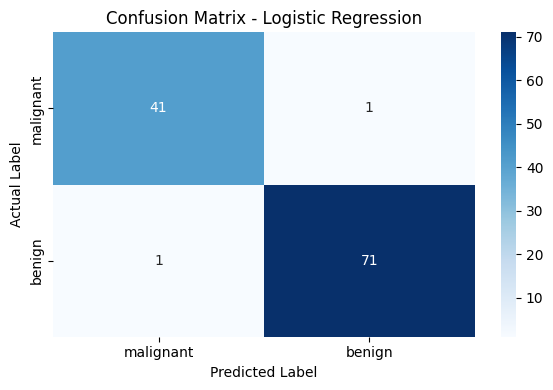

In [6]:

# Step 6: Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


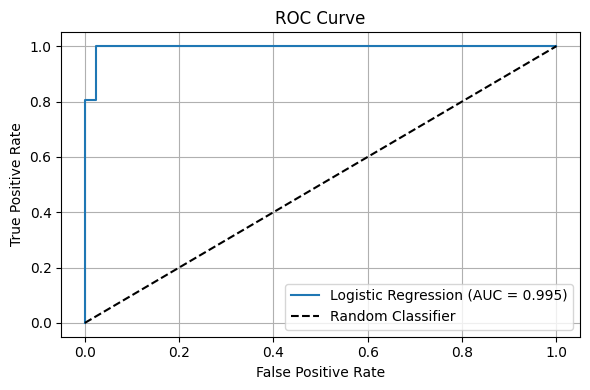

In [7]:

# Step 7: ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

# Step 8: Load Iris dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris, y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

# One-vs-Rest classifier
ovr_model = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(
        LogisticRegression(max_iter=5000, random_state=42)
    )
)
ovr_model.fit(X_train_i, y_train_i)

# Multinomial (Softmax) Logistic Regression
softmax_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        solver="lbfgs",
        max_iter=5000,
        random_state=42
    )
)
softmax_model.fit(X_train_i, y_train_i)

# Compare performance
models = {
    "One-vs-Rest": ovr_model,
    "Softmax (Multinomial)": softmax_model
}

results = []

for name, clf in models.items():
    pred = clf.predict(X_test_i)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_i, pred),
        "Precision (macro)": precision_score(
            y_test_i, pred, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test_i, pred, average="macro", zero_division=0
        ),
        "F1-Score (macro)": f1_score(
            y_test_i, pred, average="macro", zero_division=0
        )
    })

comparison = pd.DataFrame(results).round(4)
display(comparison)


,Model,Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
0,One-vs-Rest,0.9000,0.9024,0.9000,0.8997
1,Softmax (Multinomial),0.9333,0.9333,0.9333,0.9333
